# NumPy 1: Por qué arrays + `np.load`

_Autor=Thomas_Gonzalez

Este notebook muestra qué es un array de NumPy y por qué conviene usarlo en vez de listas y bucles, con fotos reales de una estrella tomadas por un telescopio espacial. Cubre:

1. Qué es un array
2. Cargar los datos y mirar una foto
3. Sumar la foto: bucle contra NumPy
4. Comparar la velocidad

Este notebook asume el notebook de Fundamentos de Python: listas, loops `for` e `import numpy as np`.

---

### Prompts de profundización

Al final de cada tema hay unos prompts para que los usen con su chatbot de confianza y profundicen más.

## 0. Prerrequisitos

Para correr este notebook, deben asegurarse de haber creado el virtual environment de python siguiendo las instrucciones del README. Una vez creado, selecciona el kernel del notebook.

Los datos están en la carpeta `data/`, al lado de esta carpeta `notebooks/`.

Para instalar python, el manejador de paquetes UV, los ambientes de conda y configurar Visual Studio Code para correr y editar Jupyter Notebooks en él, revisen los siguientes recursos:

- [Cómo instalar Conda](https://youtu.be/TJor7z8g8FA?si=7-VUSQJiew6Hu_gW)
- [Instalación de UV](https://youtu.be/YzOLOlH1jQk?si=2hFk6aAh8gCoMvuo)
- [VS Code + Jupyter Notebooks](https://youtu.be/rL1usXq4bgE?si=2b5REnUzVBMDxWfF)

## 1. Qué es un array

En el notebook de Fundamentos de Python, `np.sum` recibió una lista y la convirtió en un arreglo de NumPy. Aquí hacemos esa conversión a mano para ver qué es ese arreglo.


In [58]:
import numpy as np

In [60]:
lista = [1,2,3,4,5]
lista

[1, 2, 3, 4, 5]

In [61]:
array = np.array(lista)
array

array([1, 2, 3, 4, 5])

In [62]:
lista[0] = 3.14
lista

[3.14, 2, 3, 4, 5]

In [63]:
array[0] = 3.14
array

array([3, 2, 3, 4, 5])

In [67]:
type(array[0])

numpy.int64

Un array obliga a que todos sus números sean del mismo tipo; una lista no.

id nos va a decir la direcion de memoria de cada variable.

In [68]:
id(lista[0]),id(lista[1])

(140612935302480, 93829547105008)

In [69]:
id(array[0]),id(array[1])

(140611462297584, 140611462297584)

**Prompts de profundización:**

- `¿Cómo guarda Python una lista en memoria y cómo lo hace un array de NumPy?`
- `¿Qué significa que una operación de NumPy esté vectorizada?`
- `¿Qué es el prefeching y porque es mas rapido tener datos continuos?`
- `¿Qué pasa si creo un array de NumPy mezclando números y texto?`

## 2. Cargar los datos y mirar una foto

Un archivo `.npy` guarda un array tal cual. `np.load` lo trae de vuelta en una línea: aquí, todas las fotos que un telescopio tomó de una estrella.

In [70]:
cube = np.load("../data/flux_cube.npy")

print(type(cube))

<class 'numpy.ndarray'>


`cube[0]` saca la primera foto, igual que `lista[0]` saca el primer elemento de una lista.

In [71]:
frame = cube[0]

# Only changes how arrays are displayed (no decimals), not their values
np.set_printoptions(precision=0, suppress=True)
print(frame)

[[  80.   81.   85.   82.   81.   78.   83.   87.   82.   84.   81.]
 [  88.   89.   89.   84.   83.   83.   90.   88.   84.   80.   76.]
 [ 104.  115.  123.  122.  109.  131.  167.  118.   92.   81.   78.]
 [ 119.  162.  230.  322.  723. 1351.  641.  225.  100.   85.   82.]
 [ 132.  232.  538. 1200. 3525. 5532. 1982.  332.   97.   87.   83.]
 [ 132.  303.  750. 1337. 3505. 7897. 4321.  220.   88.   83.   79.]
 [ 157.  349.  701. 1147. 2001. 3058. 1763.  200.  103.   83.   79.]
 [ 148.  286.  485.  793. 1130. 1323.  680.  326.  147.   86.   76.]
 [ 118.  174.  272.  254.  488.  542.  368.  372.  215.   82.   77.]
 [ 105.  119.  140.  120.  158.  199.  201.  197.  138.   80.   76.]
 [  92.   98.   96.   93.  104.  126.  137.  133.  100.   78.   79.]]


![visualizacion de que es un ndarray](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Feli.thegreenplace.net%2Fimages%2F2015%2Frow-major-2D.png&f=1&nofb=1&ipt=a589408888bbc304dcabf65191f49f2ce4b0053be417b30eaca0405fde846f90&ipo=images)

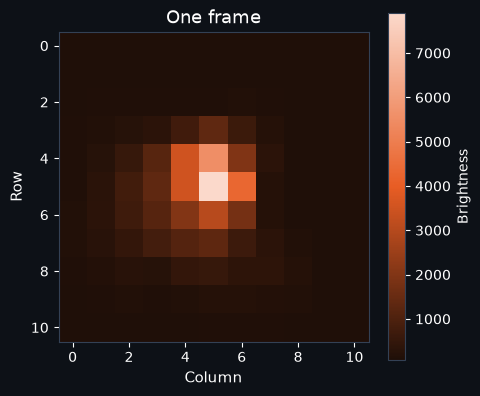

In [72]:
from plot_helpers import plot_frame

plot_frame(frame)

**Prompts de profundización:**

- `¿Qué es un archivo .npy y en qué se diferencia de un CSV?`
- `¿Qué significa el "nd" en numpy.ndarray?`
- `¿Cómo se representa una imagen digital como una tabla de números?`
- `¿Cómo puedo guardar el array como un archivo npy?`

## 3. Sumar la foto: bucle contra NumPy

¿Cuánto brillo hay en toda la foto? Hay que sumar sus 121 números. Primero con bucles, como en el notebook de Fundamentos de Python. La foto es una lista de filas, así que hace falta un `for` dentro de otro `for`.

In [73]:
total = 0.0
for row in frame:
    for element in row:
        total += element

total

np.float32(60327.945)

In [74]:
frame.sum()

np.float32(60327.953)

Ahora con NumPy, la misma función que en el notebook de Fundamentos de Python sumó una lista:

**Prompts de profundización:**

- `¿Por qué sumar los mismos números en distinto orden puede dar un resultado ligeramente distinto en un computador?`
- `¿Qué es la suma por pares (pairwise summation) y por qué la usa NumPy?`
- `¿Cómo funciona un for anidado en Python?`

## 4. Comparar la velocidad

`%%timeit` es un comando de Jupyter: corre la celda muchas veces y muestra cuánto tarda en promedio. Comparamos las dos formas de sumar, sobre el array y sobre la misma foto convertida en lista.

frame_list = frame.tolist()

print(type(frame_list))

In [75]:
frame_list = frame.tolist()

print(type(frame_list))

<class 'list'>


In [ ]:
# los invito a probar con id la continuidad
# id(frame_list[0][0]),id(frame_list[1][0])

In [77]:
%%timeit
total=0
for row in frame:
    for elemnt in row:
        total += 1

4.53 μs ± 67.4 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [78]:
%%timeit
total=0
for row in frame_list:
    for elemnt in row:
        total += 1

928 ns ± 4.63 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [79]:
%%timeit
np.sum(frame)

604 ns ± 4.95 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [80]:
%%timeit
np.sum(frame_list)

3.03 μs ± 16.7 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


**Prompts de profundización:**

- `¿Por qué recorrer un array de NumPy con un for de Python es más lento que recorrer una lista?`
- `¿Cómo mide %timeit el tiempo de ejecución y por qué repite la medición tantas veces?`
- `¿Por qué la ventaja de NumPy sobre los bucles crece cuando hay más datos?`

## 5. ¿Qué viene?

El cubo tiene una forma. ¿Qué significa cada uno de estos números? Eso es el siguiente notebook.

In [81]:
print(cube.shape)

(1440, 11, 11)


## Referencias

- NumPy Developers. *NumPy documentation*. https://numpy.org/doc/stable/
- NumPy Developers. *numpy.load*. https://numpy.org/doc/stable/reference/generated/numpy.load.html

---

*Última actualización: octubre 2026*